# BiciLogic 05 · Balanced districting, and *balance of what?*

The baseline (notebook 04) used **k-means** = Euclidean distance + no balance. Here we fix both:

1. assign demand to zones by **network distance** (the metric the courier actually travels), and
2. **balance** the zones.

But the key question is *balance of what?* The real workload of a zone is **the routed tour from the depot through its stops** - not the number of points, and not the straight-line spread. We will balance point counts first, then **measure the real routed workload** and see what happens.

In [1]:
import sys
sys.path.append("../src")

import osmnx as ox
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans

from geo_utils import distance_matrix
from vrp import solve_vrp

ox.settings.use_cache = True
G = ox.graph_from_place("Ixelles, Brussels, Belgium", network_type="bike", simplify=True)
Gp = ox.project_graph(G)
scc = max(nx.strongly_connected_components(Gp), key=len)
Gs = Gp.subgraph(scc).copy()
nodes = list(Gs.nodes)
coords = np.array([[Gs.nodes[n]["x"], Gs.nodes[n]["y"]] for n in nodes])

In [2]:
# demand model (3 hotspots + background), plus a central depot
rng = np.random.default_rng(3)
hot = coords[rng.choice(len(nodes), size=3, replace=False)]
d_near = np.sqrt(((coords[:, None, :] - hot[None, :, :]) ** 2).sum(-1)).min(axis=1)
w = np.exp(-d_near / 500.0) + 0.15
w /= w.sum()
demand_idx = rng.choice(len(nodes), size=180, replace=False, p=w)
demand_nodes = [nodes[i] for i in demand_idx]
demand_xy = coords[demand_idx]
n, k = len(demand_nodes), 3

cxy = demand_xy.mean(axis=0)
depot = ox.nearest_nodes(Gs, X=cxy[0], Y=cxy[1])

## 1. Two partitions

- **k-means**: Euclidean, unconstrained.
- **balanced-network**: assign each point to a seed by *network* distance, with each zone forced to ~n/k points. The balanced assignment is a **tiled Hungarian**: replicate each seed into `n/k` slots, then solve a one-to-one assignment (`linear_sum_assignment`) minimizing total network distance - so each seed receives at most `n/k` points.

In [3]:
# baseline k-means
km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(demand_xy)
labels_km = km.labels_

# seeds = k-means centroids snapped to graph nodes
seeds = ox.nearest_nodes(Gs, X=km.cluster_centers_[:, 0], Y=km.cluster_centers_[:, 1])

# network distance from each seed to every demand node
netdist = np.zeros((n, k))
for z, s in enumerate(seeds):
    dist = nx.single_source_dijkstra_path_length(Gs, s, weight="length")
    netdist[:, z] = [dist.get(nd, 1e9) for nd in demand_nodes]

# balanced assignment (tiled Hungarian)
cap = int(np.ceil(n / k))
cost = np.repeat(netdist, cap, axis=1)         # seed0 x cap, seed1 x cap, ...
row, col = linear_sum_assignment(cost)
labels_bal = np.empty(n, dtype=int)
labels_bal[row] = col // cap

## 2. Measure the *real* workload (routed from the depot)

For each zone we solve a TSP from the depot through its stops. That tour length is the courier's actual workload - the thing we truly want balanced.

In [4]:
def zone_workload(zone_node_list):
    ds = distance_matrix(Gs, [depot] + zone_node_list)
    _, L = solve_vrp(ds, 1, objective="sum", time_limit_s=3)
    return L[0]

def report(name, labels):
    counts, loads = [], []
    for z in range(k):
        zn = [demand_nodes[i] for i in range(n) if labels[i] == z]
        counts.append(len(zn)); loads.append(zone_workload(zn))
    counts, loads = np.array(counts), np.array(loads)
    print(f"{name}")
    print(f"  points/zone   : {counts.tolist()}  (imbalance {counts.max()/counts.min():.2f})")
    print(f"  routed km/zone: {(loads/1000).round(1).tolist()}  (imbalance {loads.max()/loads.min():.2f})")

report("k-means (Euclidean)", labels_km)
report("balanced (network distance)", labels_bal)

k-means (Euclidean)
  points/zone   : [75, 54, 51]  (imbalance 1.47)
  routed km/zone: [12.9, 14.3, 10.6]  (imbalance 1.35)


balanced (network distance)
  points/zone   : [60, 60, 60]  (imbalance 1.00)
  routed km/zone: [9.6, 15.5, 11.7]  (imbalance 1.62)


## 3. The lesson

Balancing **point counts** (60/60/60) can make the **routed workload** *more* imbalanced, not less. Reason: a zone's workload is roughly

$$\text{workload} \;\approx\; \text{depot access} \;+\; \beta\sqrt{n\,A}$$

(the **Beardwood-Halton-Hammersley** law for the expected TSP length over n points in area A). Same n but a larger area A, or a zone farther from the depot, means more kilometers. So **equal counts != equal work**.

**Conclusion:** we must balance the *routed workload* directly - which couples districting and routing (the workload of a zone depends on its own route). That coupling is what the next steps handle: balance the routed cost (by swapping boundary points between zones, or via the BHH estimate), then make it **robust** to day-to-day demand.

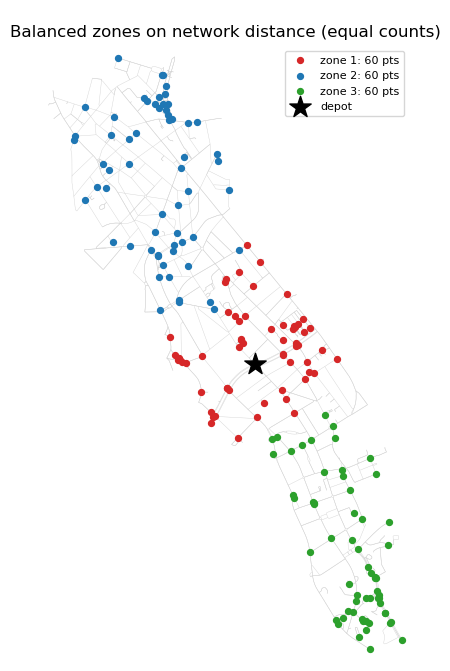

In [5]:
fig, ax = ox.plot_graph(Gs, node_size=0, edge_linewidth=0.3, edge_color="lightgray",
                        bgcolor="white", show=False, close=False)
colors = ["tab:red", "tab:blue", "tab:green"]
for z in range(k):
    m = labels_bal == z
    ax.scatter(demand_xy[m, 0], demand_xy[m, 1], s=18, c=colors[z], zorder=4,
               label=f"zone {z+1}: {int(m.sum())} pts")
ax.scatter(Gs.nodes[depot]["x"], Gs.nodes[depot]["y"], marker="*", s=260, c="black",
           zorder=6, label="depot")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Balanced zones on network distance (equal counts)")
plt.show()